In [30]:
import pandas as pd
df = pd.read_csv("Bassac_01_train.csv", nrows=10000)
df

,Date,WL
0,19/06/2020 12:00,1.18
1,19/06/2020 12:15,1.16
2,19/06/2020 12:30,1.14
3,19/06/2020 12:45,1.12
4,19/06/2020 13:00,1.10
...,...,...
9995,01/10/2020 14:45,3.30
9996,01/10/2020 15:00,3.28
9997,01/10/2020 15:15,3.28
9998,01/10/2020 15:30,3.28


In [31]:
df.describe()

,WL
count,10000.000000
mean,2.217425
std,0.846155
min,0.690000
25%,1.420000
50%,2.300000
75%,2.980000
max,3.600000


In [32]:
df.isnull().sum()

Date    0
WL      0
dtype: int64

In [33]:
df["Date"] = pd.to_datetime(df["Date"])

daily_df = (
    df.set_index("Date")["WL"]
      .resample("1D")
      .mean()
      .reset_index()
)

/var/folders/hx/_8svmq_s3mj0kmgn91bbq7b40000gn/T/ipykernel_12055/2333979257.py:1: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Date"] = pd.to_datetime(df["Date"])


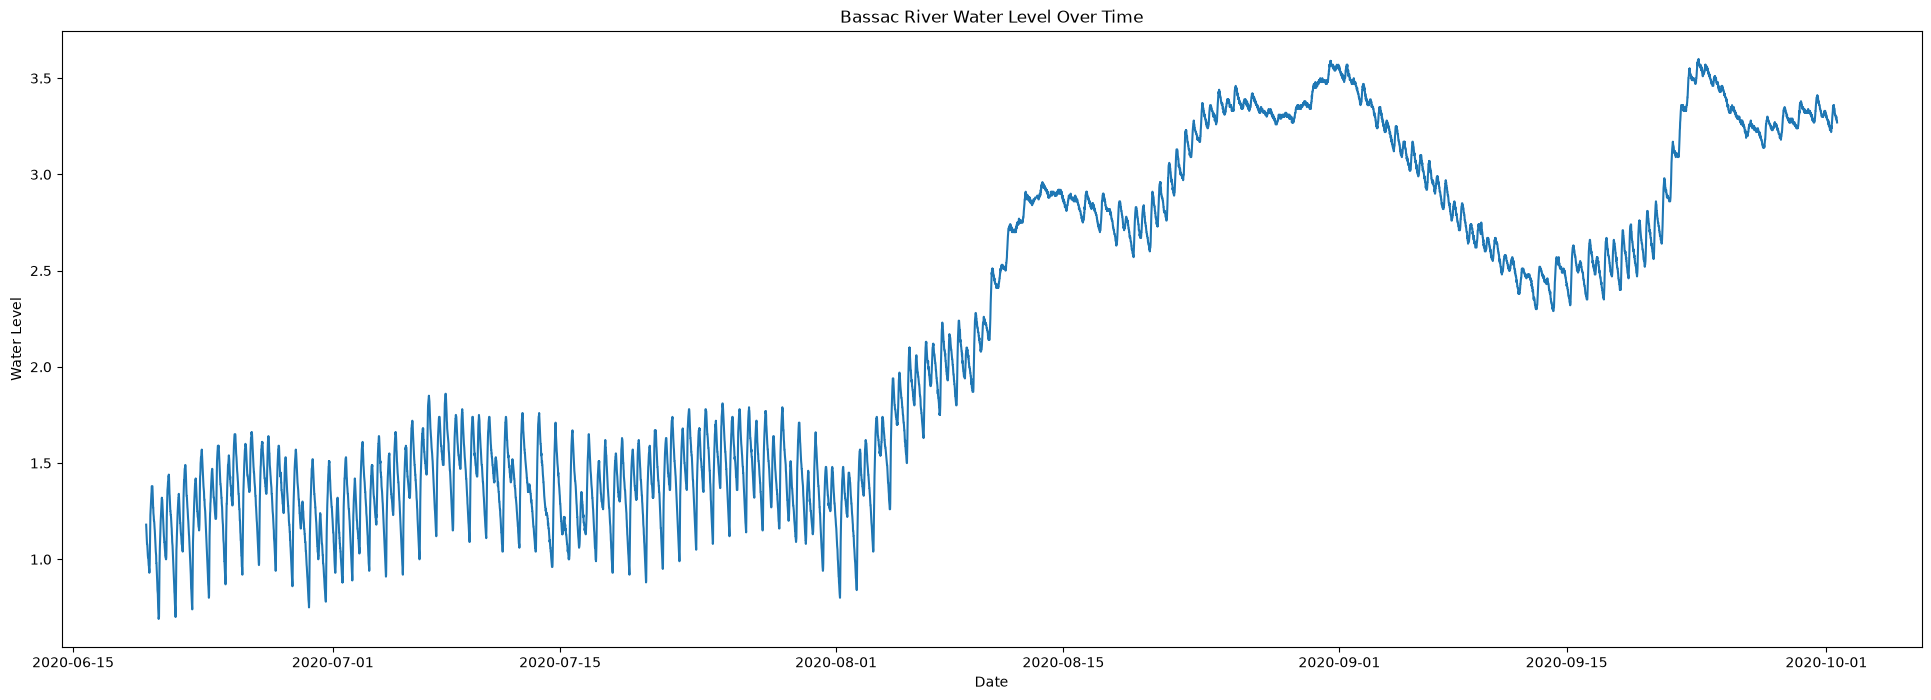

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(24,8))

plt.plot(df["Date"], df["WL"])

plt.xlabel("Date")
plt.ylabel("Water Level")
plt.title("Bassac River Water Level Over Time")

plt.show()

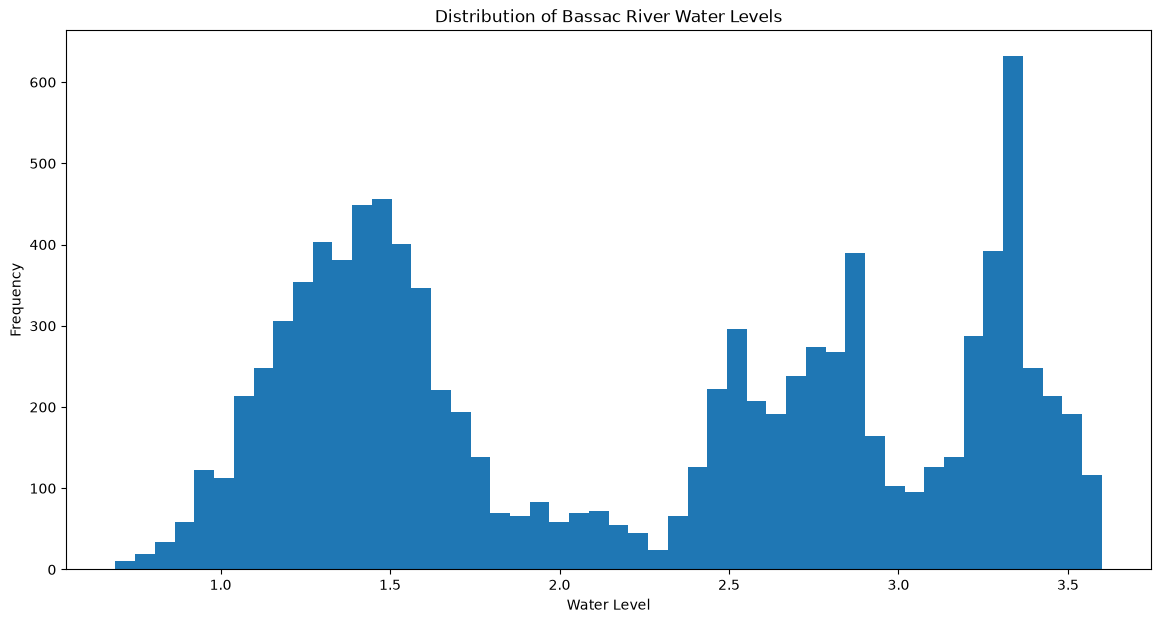

In [35]:
plt.figure(figsize=(14, 7))

plt.hist(df["WL"], bins=50)
plt.xlabel("Water Level")
plt.ylabel("Frequency")
plt.title("Distribution of Bassac River Water Levels")

plt.show()

/var/folders/hx/_8svmq_s3mj0kmgn91bbq7b40000gn/T/ipykernel_12055/67421738.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["WL"].dropna(), vert=False)


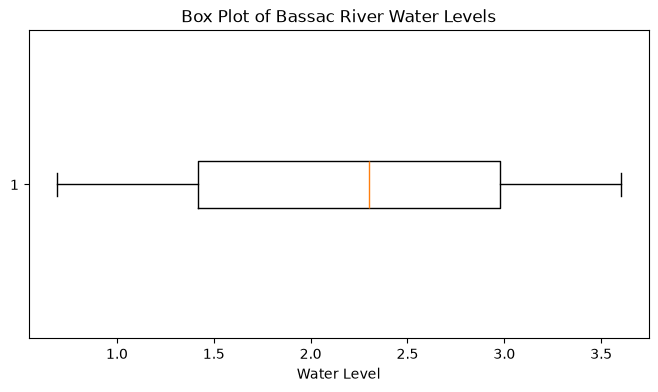

In [36]:
plt.figure(figsize=(8, 4))

plt.boxplot(df["WL"].dropna(), vert=False)
plt.xlabel("Water Level")
plt.title("Box Plot of Bassac River Water Levels")

plt.show()

In [37]:
df["time_diff"] = df["Date"].diff()

df["time_diff"].value_counts().head(10000)

time_diff
0 days 00:15:00    9999
Name: count, dtype: int64

In [38]:
daily_df.to_csv("water_level_daily.csv", index=False)